In [1]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

df = pd.read_csv(r"C:\Users\naila\OneDrive\Documentos\ironhack\lab-eda-bivariate\amz_uk_price_prediction_dataset.csv")

In [3]:
# 1. Asegurar la limpieza de datos (Paso previo necesario)
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1
df_clean = df[(df['price'] >= (q1 - 1.5 * iqr)) & (df['price'] <= (q3 + 1.5 * iqr))].copy()

# 2. Crear la tabla cruzada (Crosstab)
ct = pd.crosstab(df_clean['category'], df_clean['isBestSeller'])

# 3. Pruebas Estadísticas
chi2, p_val, dof, expected = chi2_contingency(ct)

# 4. Cálculo de Cramér's V
n = ct.sum().sum()
phi2 = chi2 / n
r, k = ct.shape
cramers_v = np.sqrt(phi2 / min(k - 1, r - 1))

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_val:.4f}")
print(f"Cramér's V: {cramers_v:.4f}")


Chi-square statistic: 32142.6349
P-value: 0.0000
Cramér's V: 0.1232


In [5]:


# --- PASO 0: ELIMINACIÓN DE OUTLIERS EN PRECIOS ---

def remove_price_outliers(data: pd.DataFrame) -> pd.DataFrame:
    """
    Elimina los outliers de la columna 'price' utilizando el método IQR.
    """
    q1: float = data['price'].quantile(0.25)
    q3: float = data['price'].quantile(0.75)
    iqr_value: float = q3 - q1
    
    lower_bound: float = q1 - 1.5 * iqr_value
    upper_bound: float = q3 + 1.5 * iqr_value
    
    # Filtramos el dataframe original
    filtered_df = data[(data['price'] >= lower_bound) & (data['price'] <= upper_bound)]
    return filtered_df

# Creamos el dataframe limpio para los siguientes pasos
df_clean: pd.DataFrame = remove_price_outliers(df)



C:\Users\naila\AppData\Local\Temp\ipykernel_21304\484901745.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x='price', y='category', palette='muted')


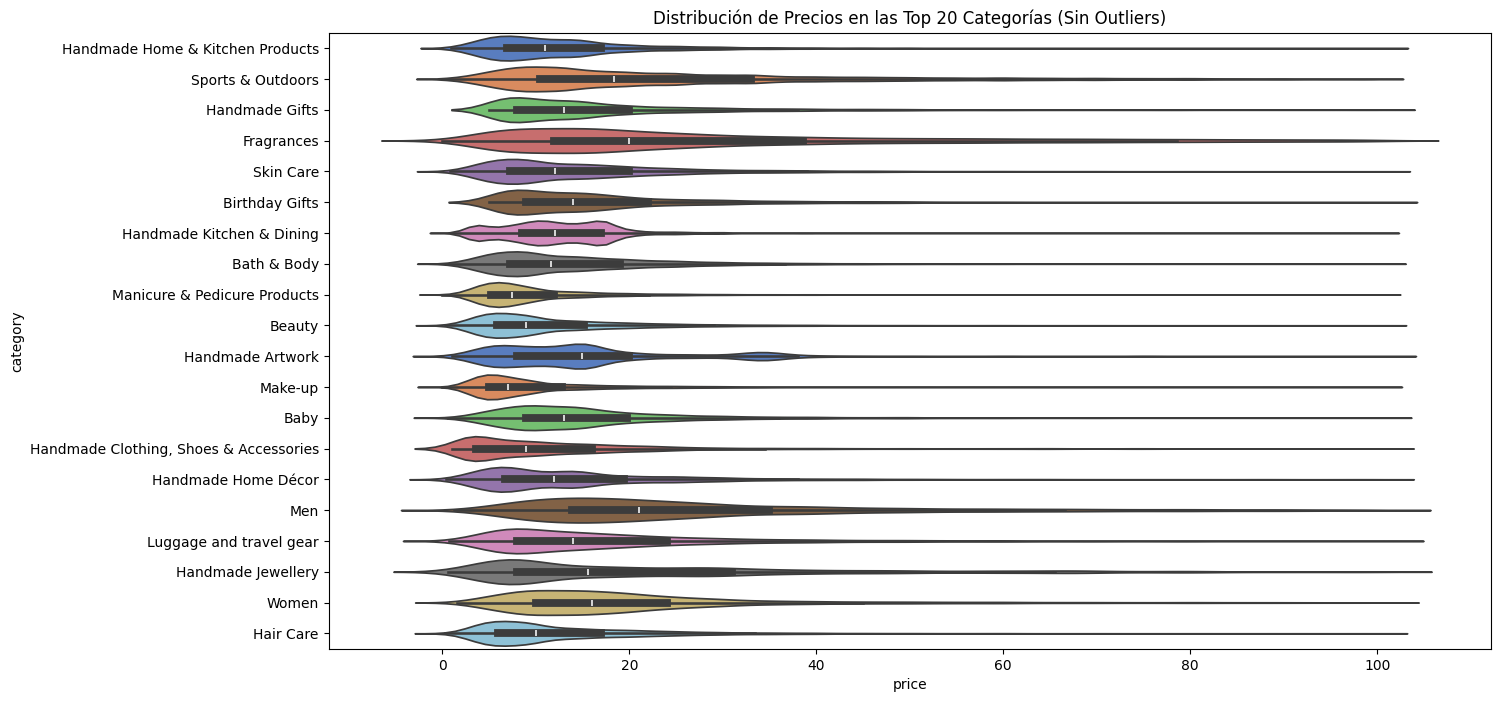

Categoría con mayor precio mediano: Desktop PCs (£74.0)


In [8]:
# --- PASO 1: VIOLIN PLOTS (PRECIO POR CATEGORÍA) ---

# Identificamos las 20 categorías con más productos
top_20_cat_names = df_clean['category'].value_counts().head(20).index
df_top_20: pd.DataFrame = df_clean[df_clean['category'].isin(top_20_cat_names)]

plt.figure(figsize=(15, 8))
sns.violinplot(data=df_top_20, x='price', y='category', palette='muted')
plt.title('Distribución de Precios en las Top 20 Categorías (Sin Outliers)')
plt.show()

# Cálculo global: Categoría con el precio mediano más alto
# Usamos el dataframe limpio pero sin filtrar por las top 20
median_prices = df_clean.groupby('category')['price'].median().sort_values(ascending=False)
print(f"Categoría con mayor precio mediano: {median_prices.index[0]} (£{median_prices.iloc[0]})")



C:\Users\naila\AppData\Local\Temp\ipykernel_21304\2404852649.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_10, x='category', y='price', estimator=np.mean, palette='viridis')


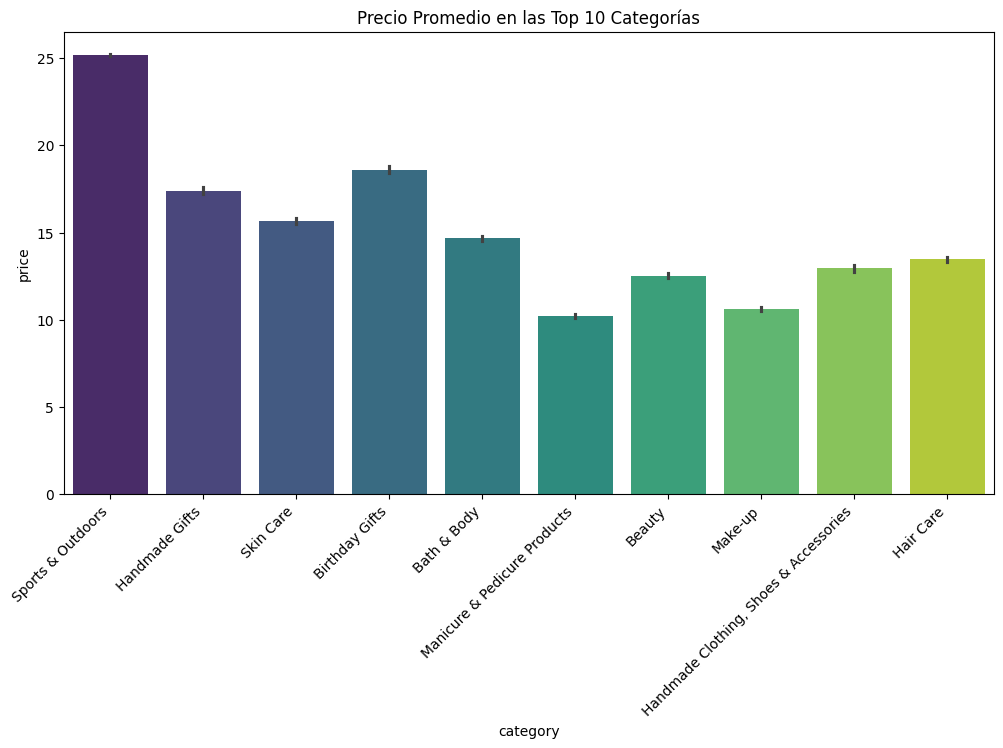

In [10]:
# --- PASO 2: BAR CHARTS (PRECIO PROMEDIO) ---

# Top 10 categorías por conteo
top_10_cat_names = df_clean['category'].value_counts().head(10).index
df_top_10: pd.DataFrame = df_clean[df_clean['category'].isin(top_10_cat_names)]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_top_10, x='category', y='price', estimator=np.mean, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Precio Promedio en las Top 10 Categorías')
plt.show()


C:\Users\naila\AppData\Local\Temp\ipykernel_21304\705097752.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10, x='stars', y='category', palette='Set3')


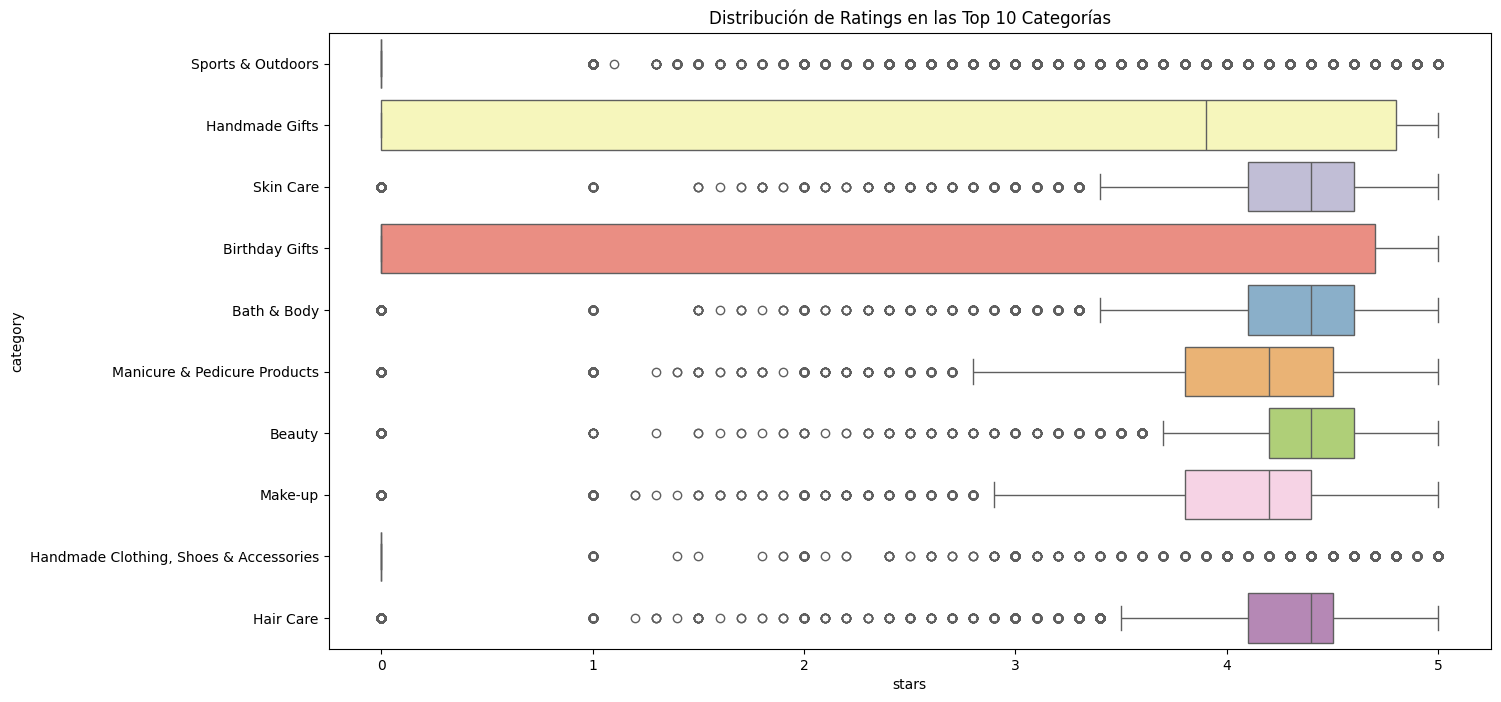

Categoría con mayor rating mediano: Computer Memory (Stars: 4.7)


In [12]:
# --- PASO 3: BOX PLOTS (RATINGS POR CATEGORÍA) ---

plt.figure(figsize=(15, 8))
# Usamos el top 10 para que el gráfico sea legible
sns.boxplot(data=df_top_10, x='stars', y='category', palette='Set3')
plt.title('Distribución de Ratings en las Top 10 Categorías')
plt.show()

# Categoría global con el rating mediano más alto
median_ratings = df_clean.groupby('category')['stars'].median().sort_values(ascending=False)
print(f"Categoría con mayor rating mediano: {median_ratings.index[0]} (Stars: {median_ratings.iloc[0]})")

In [14]:
# Categoría global con el rating mediano más alto
median_ratings = df_clean.groupby('category')['stars'].median().sort_values(ascending=False)
print(f"Categoría con mayor rating mediano: {median_ratings.index[0]} (Stars: {median_ratings.iloc[0]})")

Categoría con mayor rating mediano: Computer Memory (Stars: 4.7)


In [15]:
correlation: float = df_clean['price'].corr(df_clean['stars'])

print(f"Coeficiente de correlación entre Precio y Rating: {correlation:.4f}")

# Interpretación:
# - Cerca de 1: Relación positiva fuerte.
# - Cerca de 0: No hay relación lineal.
# - Cerca de -1: Relación negativa fuerte.

Coeficiente de correlación entre Precio y Rating: -0.0777


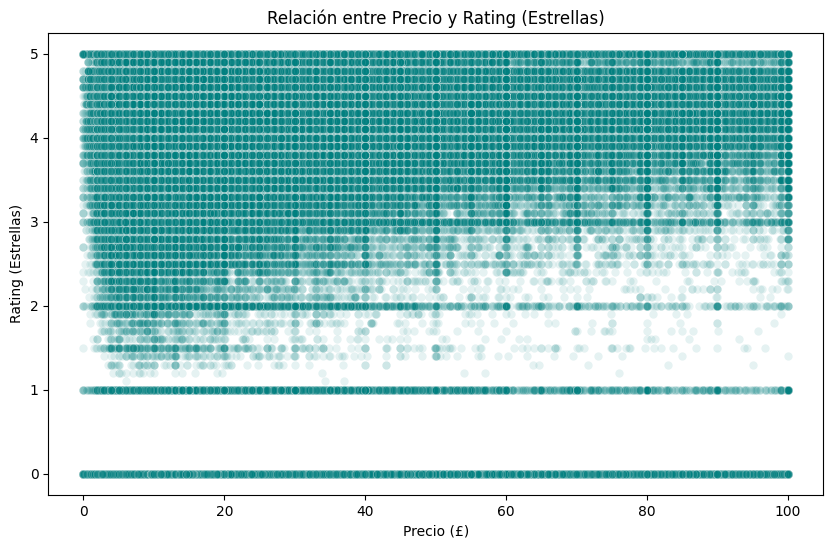

In [16]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='price', y='stars', alpha=0.1, color='teal')
plt.title('Relación entre Precio y Rating (Estrellas)')
plt.xlabel('Precio (£)')
plt.ylabel('Rating (Estrellas)')
plt.show()

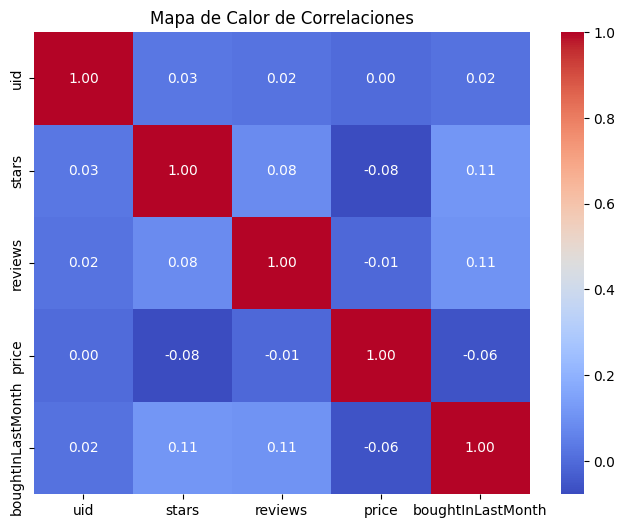

In [17]:
plt.figure(figsize=(8, 6))
# Seleccionamos solo columnas numéricas
numeric_df = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlaciones')
plt.show()

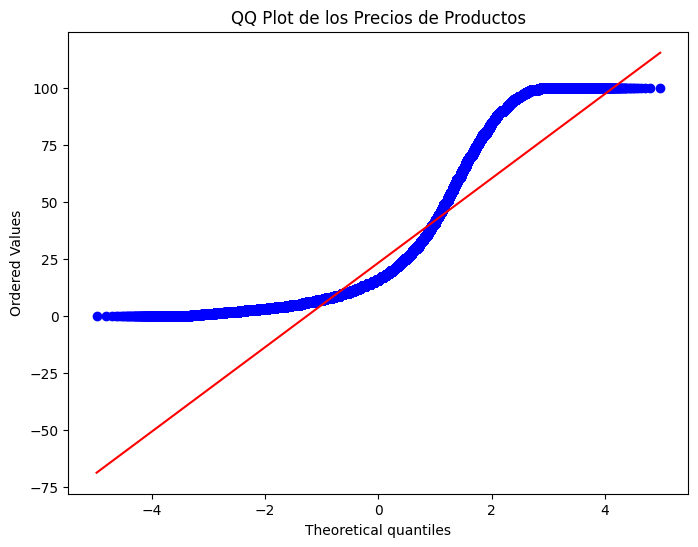

In [ ]:
from scipy import stats 
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title('QQ Plot de los Precios de Productos')
plt.show()